# A small VLM in 8 GB: visual question answering on robot-workspace images

Dual encoders (notebook 01) score image-text pairs, and Florence-2 (notebook 02) answers a fixed
set of task prompts. A **vision-language model (VLM)** goes further. It is a language model
that reads images and answers arbitrary questions in free text. That flexibility is attractive
for robots ("is the mug to the left of the laptop?", "which object do I use to make a call?").
It is also where the most dangerous failure modes live: confident, fluent, wrong answers.

This notebook runs **Qwen3.5-0.8B** (`Qwen/Qwen3.5-0.8B`, Apache-2.0, 1.75 GB of bf16 weights,
loaded natively in `transformers`, no remote code) on an 8 GB laptop GPU and measures it
honestly:

1. hand-labelled questions about real robot-workspace frames (TUM RGB-D `fr1_desk`);
2. latency (time to first token, decode tokens/s) and peak VRAM as a function of image resolution;
3. 850 automatically generated questions with known answers on coco128: object presence
   (hallucination), counting and spatial relations;
4. a qualitative failure analysis.

**What you'll learn**
- how a VLM turns an image into tokens (patches, 2 x 2 merging, the chat template) and what that costs;
- prefill vs decode, and why the visual-token budget is the main latency knob;
- how to build cheap, automatic VQA tests from detection labels (POPE-style presence, counting, left/right and above/below);
- how small VLMs fail: hallucinated objects, counting, spatial relations, and how to report accuracy with confidence intervals and baselines.

**Prerequisites:** notebooks 01-02, the transformer decoder and autoregressive generation.
Run `make data-13_vision_language` and the probe benchmark
`python projects/13_vision_language/scripts/eval_vqa_probes.py` (about 2 minutes; this notebook
loads its CSV). The notebook itself runs in under a minute on an RTX 5060 Laptop GPU (8 GB).

## Setup

The model wrapper `vl.SmallVLM` loads the checkpoint pinned in `configs/models.yaml` in bf16,
applies the chat template, decodes greedily and times every call with CUDA synchronisation.

In [1]:
# --- Setup: imports, device, repo-relative paths, plotting style ---
# vl_common.py (in this project's scripts/ folder) wraps the model loading and the
# small pure functions (prompt ensembling, answer parsing, ...) that are unit-tested.
import os
import sys

os.environ.setdefault("HF_HUB_DISABLE_PROGRESS_BARS", "1")  # keep notebook outputs clean

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import transformers
from IPython.display import display

import cvlab.device
from cvlab import viz
from cvlab.io import data_dir, project_dir

transformers.logging.set_verbosity_error()  # silence config/loader chatter
transformers.utils.logging.disable_progress_bar()

PROJECT = "13_vision_language"
sys.path.insert(0, str(project_dir(PROJECT) / "scripts"))
import vl_common as vl  # noqa: E402

device = cvlab.device.setup(seed=0)  # seeds RNGs, picks the GPU, prints versions
viz.set_style()
RESULTS = project_dir(PROJECT) / "results"
RESULTS.mkdir(exist_ok=True)
TUM_RGB = data_dir("tum", "fr1_desk", "rgbd_dataset_freiburg1_desk", "rgb")
print("transformers", transformers.__version__, "| results ->", vl.rel(RESULTS))

import json
import textwrap

COCO128 = data_dir("ultralytics", "coco128")
coco = vl.load_yolo_split(COCO128 / "images" / "train2017", COCO128 / "labels" / "train2017")
frames, desk_qs = vl.desk_questions()
desk = {k: vl.load_rgb(p) for k, p in frames.items()}
print(f"{len(desk_qs)} hand-labelled questions on {len(desk)} desk frames | coco128: {len(coco)} images")

python 3.12.16 | torch 2.11.0+cu128 (CUDA 12.8) | torchvision 0.26.0+cu128 | numpy 2.5.4 | opencv 5.0.0
device: cuda | GPU: NVIDIA GeForce RTX 5060 Laptop GPU (7.53 GB, sm_120)
transformers 5.22.2 | results -> projects/13_vision_language/results
14 hand-labelled questions on 5 desk frames | coco128: 128 images


## 1. Theory: how a VLM reads an image

**Visual tokens.** The image is resized, keeping its aspect ratio, so that both sides are
multiples of 32 px and the area lies within a pixel budget $[\text{min\_pixels}, \text{max\_pixels}]$.
A ViT cuts it into 16 x 16 px patches. A *merger* then concatenates each 2 x 2 group of patch
features and projects it with an MLP to the language model's width. One visual token therefore
covers 32 x 32 px:

$$N_\text{vis} = \frac{H}{32}\cdot\frac{W}{32}, \qquad 640\times480 \;\rightarrow\; 20 \cdot 15 = 300 \text{ tokens}.$$

**Fusion.** The chat template contains a placeholder `<|image_pad|>` that the processor
repeats $N_\text{vis}$ times. The language model replaces those token embeddings with the visual
features. Positions use multimodal RoPE (separate rotary components for time, height and width),
so the decoder knows where each visual token sits in the image.

**Two phases of generation.**
*Prefill* runs the vision encoder and processes all $N_\text{prompt}$ tokens in parallel. Its
cost grows with $N_\text{vis}$ and sets the **time to first token (TTFT)**. *Decode* then
produces one token per forward pass, re-using cached keys and values. At batch size 1 every step
reads all the weights, so decode is memory-bound and its speed (tokens/s) barely depends on the image.

**Qwen3.5's hybrid decoder.** Of the 24 decoder layers, 18 are *Gated DeltaNet* linear-attention
layers. They keep a fixed-size recurrent state instead of a growing KV cache. The other 6 (every
4th layer) are full softmax attention. Only those 6 layers cache keys and values:

$$\text{KV bytes per token} = 2 \cdot L_\text{full} \cdot n_\text{kv heads} \cdot d_\text{head} \cdot 2\,\text{B (bf16)}.$$

`transformers` ships a reference PyTorch implementation of the linear-attention kernels.
The optimised `flash-linear-attention` / `causal-conv1d` kernels are not installed here, so
the speeds below are those of the reference path.

## 2. Load the model and inspect it

We print parameter counts per component and compute the KV-cache cost per token from the
config.

In [2]:
# --- Load Qwen3.5-0.8B in bf16; parameter breakdown and KV-cache size from the config ---
with vl.vram_meter() as mem_load:
    vlm = vl.SmallVLM(device)
m, tc = vlm.model, vlm.model.config.text_config
print(f"{type(m).__name__}: {vl.n_params(m):.0f} M parameters, weights on GPU {mem_load.delta_mb:.0f} MiB")
print(f"  vision encoder + merger   {vl.n_params(m.model.visual):6.1f} M")
print(f"  language model            {vl.n_params(m.model.language_model):6.1f} M "
      f"(of which token embeddings {tc.vocab_size * tc.hidden_size / 1e6:.1f} M, tied with the LM head)")
n_full = tc.layer_types.count("full_attention")
kv_bytes = 2 * n_full * tc.num_key_value_heads * tc.head_dim * 2
print(f"decoder: {tc.num_hidden_layers} layers = {tc.layer_types.count('linear_attention')} linear-attention "
      f"+ {n_full} full-attention | KV cache {kv_bytes / 1024:.0f} KiB per token "
      f"-> {1000 * kv_bytes / 2**20:.1f} MiB for a 1,000-token context")

Qwen3_5ForConditionalGeneration: 853 M parameters, weights on GPU 1656 MiB
  vision encoder + merger    100.6 M
  language model             752.4 M (of which token embeddings 254.3 M, tied with the LM head)
decoder: 24 layers = 18 linear-attention + 6 full-attention | KV cache 12 KiB per token -> 11.7 MiB for a 1,000-token context


## 3. The chat template and the token budget

We look at the exact text that enters the model for one question, and count the tokens after
the processor expands the image placeholder. Non-thinking mode is the default for this model;
we pass `enable_thinking=False` explicitly (the template then inserts an empty `<think>` block)
because the model card warns that Qwen3.5-0.8B is prone to loops in thinking mode.

In [3]:
# --- Render the chat template for one question and count prompt / visual tokens ---
msgs = [{"role": "user", "content": [{"type": "image", "image": desk["desk_b"]},
                                     {"type": "text", "text": "How many books are on the desk?"}]}]
text = vlm.processor.apply_chat_template(msgs, add_generation_prompt=True, tokenize=False, enable_thinking=False)
print(text)
enc = vlm.inputs(desk["desk_b"], "How many books are on the desk?")
n_vis = int((enc["input_ids"] == vlm.image_token_id).sum())
t, h, w = enc["image_grid_thw"][0].tolist()  # patch grid (16 px patches) of the resized image
print(f"image {desk['desk_b'].size} -> resized {w * 16}x{h * 16} px -> {h}x{w} patches -> "
      f"{n_vis} visual tokens (2x2 merge) | prompt length {enc['input_ids'].shape[1]} tokens")

<|im_start|>user
<|vision_start|><|image_pad|><|vision_end|>How many books are on the desk?<|im_end|>
<|im_start|>assistant
<think>

</think>


image (640, 480) -> resized 640x480 px -> 30x40 patches -> 300 visual tokens (2x2 merge) | prompt length 322 tokens


## 4. Describing a robot workspace

First a qualitative look. We ask for a short scene description and for a list of objects a
robot arm could grasp, on two desk frames. Read the answers critically and compare them with
the images (shown in the Results section).

In [4]:
# --- Free-form descriptions of two desk frames (greedy decoding) ---
for key in ["desk_b", "desk_e"]:
    for q in ["Describe this robot workspace in two sentences.",
              "List the objects on the desk that a robot arm could grasp. Answer with a comma-separated list."]:
        a = vlm.ask(desk[key], q, max_new_tokens=96)
        print(f"[{key}] Q: {q}\n  A: {textwrap.fill(a.text, 110, subsequent_indent='     ')}\n"
              f"     ({a.new_tokens} tokens in {a.latency_s:.2f} s)")

[desk_b] Q: Describe this robot workspace in two sentences.
  A: This robot workspace is a cluttered desk filled with various electronic devices, papers, and office supplies,
     suggesting a busy or active environment.
     (30 tokens in 1.02 s)


[desk_b] Q: List the objects on the desk that a robot arm could grasp. Answer with a comma-separated list.
  A: mouse, mousepad, mouse, mouse, mouse, mouse, mouse, mouse, mouse, mouse, mouse, mouse, mouse, mouse, mouse,
     mouse, mouse, mouse, mouse, mouse, mouse, mouse, mouse, mouse, mouse, mouse, mouse, mouse, mouse, mouse,
     mouse, mouse, mouse, mouse, mouse, mouse, mouse, mouse, mouse, mouse, mouse, mouse, mouse, mouse, mouse,
     mouse, mouse, mouse
     (96 tokens in 1.33 s)


[desk_e] Q: Describe this robot workspace in two sentences.
  A: This robot workspace is a cluttered desk filled with various office supplies, including a book titled
     "Multiple View Geometry," a phone, a red and blue robot camera, a game controller, and a bag of flour
     labeled "Chunk." The scene suggests a casual or informal work environment where items are scattered
     around, possibly indicating a hobbyist or student setting.
     (73 tokens in 1.03 s)


[desk_e] Q: List the objects on the desk that a robot arm could grasp. Answer with a comma-separated list.
  A: mouse, game controller, phone, keyboard, paper, book
     (15 tokens in 0.26 s)


## 5. Hand-labelled robot questions

`configs/desk_questions.yaml` holds 14 questions about the five desk frames. Their answers were
labelled by looking at the images: counting monitors, presence (including two absent objects),
left/right relations, the state of a laptop screen, reading a book title and a simple
affordance question. Answers are parsed automatically (first yes/no word, first number, and so on).

In [5]:
# --- Ask the 14 hand-labelled questions and score the free-text answers ---
qa_rows = []
for q in desk_qs:
    a = vlm.ask(desk[q["frame"]], q["question"], max_new_tokens=32)
    pred, ok = vl.score_probe(q["kind"], q["truth"], a.text)
    qa_rows.append({"frame": q["frame"], "kind": q["kind"], "question": q["question"].split("?")[0] + "?",
                    "truth": q["truth"], "answer": a.text, "correct": ok, "s": a.latency_s})
qa = pd.DataFrame(qa_rows)
print(f"correct: {qa.correct.sum()} / {len(qa)}")
with pd.option_context("display.max_colwidth", 80):
    display(qa.style.format({"s": "{:.2f}"}).map(lambda v: f"color: {'green' if v else 'red'}", subset=["correct"]))

correct: 11 / 14


,frame,kind,question,truth,answer,correct,s
0,desk_a,count,How many computer monitors are in the image?,2,2,True,0.11
1,desk_a,presence,Is there a computer mouse in the image?,True,Yes,True,0.11
2,desk_b,presence,Is there a coffee mug in the image?,True,No.,False,0.12
3,desk_b,spatial,Is the keyboard to the left or to the right of the telephone?,right,right,True,0.11
4,desk_c,state,Is the laptop screen switched on or off?,on,on,True,0.11
5,desk_c,spatial,Is the laptop to the left or to the right of the computer mouse?,left,left,True,0.11
6,desk_c,count,How many laptops are in the image?,1,2,False,0.11
7,desk_d,count,How many computer monitors are in the image?,3,3,True,0.12
8,desk_d,presence,Is there a cat in the image?,False,No,True,0.12
9,desk_e,keyword,What is the title of the blue book on the left?,['multiple view geometry'],Multiple View Geometry,True,0.14


## 6. Latency and memory vs the visual-token budget

We force the same 640 x 480 desk frame to 64, 150, 300 (native), 600 and 1,200 visual tokens by
setting both ends of the pixel budget. Raising `min_pixels` upsamples the image. For each budget we
measure:

* **TTFT**: `generate(max_new_tokens=1)`, which covers vision encoder + prefill + one decode step;
* **decode speed**: forcing 64 new tokens, $(64-1)/(t_{64} - t_\text{TTFT})$ tokens/s;
* **peak VRAM** during the 64-token generation.

In [6]:
# --- Sweep the visual-token budget: TTFT, decode tokens/s, peak VRAM ---
default_budget = vlm.pixel_budget
vlm.ask(desk["desk_b"], "Warm-up.", max_new_tokens=4)
sweep = []
for n_tok in [64, 150, 300, 600, 1200]:
    px = n_tok * 32 * 32
    vlm.set_pixel_budget(px, min_pixels=px)
    ttft = np.median([vlm.ask(desk["desk_b"], "Describe this image.", max_new_tokens=1).latency_s for _ in range(3)])
    with vl.vram_meter() as mem:
        a = vlm.ask(desk["desk_b"], "Describe this image.", max_new_tokens=64, min_new_tokens=64)
    sweep.append({"visual tokens": a.image_tokens, "prompt tokens": a.prompt_tokens, "TTFT (ms)": 1000 * ttft,
                  "64-token answer (s)": a.latency_s, "decode tok/s": (a.new_tokens - 1) / (a.latency_s - ttft),
                  "peak VRAM (MiB)": mem.peak_mb})
vlm.set_pixel_budget(default_budget[1], min_pixels=default_budget[0])  # back to the default
sweep = pd.DataFrame(sweep)
display(sweep.style.format({"TTFT (ms)": "{:.0f}", "64-token answer (s)": "{:.2f}",
                            "decode tok/s": "{:.1f}", "peak VRAM (MiB)": "{:.0f}"}))

,visual tokens,prompt tokens,TTFT (ms),64-token answer (s),decode tok/s,peak VRAM (MiB)
0,54,72,32,0.85,77.1,1710
1,140,158,43,0.88,75.5,1725
2,300,318,64,0.94,72.2,1748
3,638,656,127,0.97,74.5,1804
4,1200,1218,268,1.10,75.6,1898


## 7. Automatic VQA probes with known answers (coco128)

Hand-labelled questions do not scale. Detection labels let us generate questions with known
answers automatically, a cheap version of benchmarks such as POPE (object hallucination):

| probe | question | truth from the labels | chance / trivial baseline |
|---|---|---|---|
| presence | "Is there a {class} in the image?" | up to 2 present + 2 random absent classes per image | majority answer (about 50%; images with a single class get only one "yes" question) |
| count | "How many {plural} are in the image?" | instance count, 1-6 | always answer "1" |
| spatial | "Is the A to the left or to the right of the B?" / "above or below" | boxes separated by $\geq 5\%$ of the image along that axis | majority answer |

`scripts/eval_vqa_probes.py` asked all of them (greedy decoding, native resolution) and saved one
row per question. We report each accuracy with a 95% Wilson interval, because some probe sets
are small:

$$\hat{p} \pm \text{(Wilson)}:\quad \frac{\hat{p} + \frac{z^2}{2n} \pm z\sqrt{\frac{\hat{p}(1-\hat{p})}{n} + \frac{z^2}{4n^2}}}{1 + \frac{z^2}{n}}, \quad z = 1.96.$$

For presence we also report the POPE metrics: precision and recall of "yes", and the
**yes-ratio**. A model that hallucinates objects says "yes" too often.

In [7]:
# --- Load the probe results written by scripts/eval_vqa_probes.py and compute metrics ---
probes = pd.read_csv(RESULTS / "vqa_probes.csv", dtype={"truth": str, "pred": str})
run = json.loads((RESULTS / "vqa_probes_summary.json").read_text())
print(f"{run['n_probes']} probes, {run['model']} ({run['dtype']}, {run['decoding']}) | "
      f"wall {run['wall_time_s']:.0f} s, mean {run['mean_latency_s']:.3f} s/question, "
      f"peak VRAM {run['peak_vram_mib']:.0f} MiB on {run['gpu']}")
pres = probes[probes.kind == "presence"].assign(truth=lambda d: d.truth == "True", said_yes=lambda d: d.pred == "True")
cnt = probes[probes.kind == "count"].assign(truth=lambda d: d.truth.astype(int), pred=lambda d: pd.to_numeric(d.pred))
spa = probes[probes.kind == "spatial"].assign(axis=lambda d: np.where(d.truth.isin(["left", "right"]), "left/right", "above/below"))

def row(name, correct, baseline, note=""):
    k, n = int(np.sum(correct)), len(correct)
    lo, hi = vl.wilson_ci(k, n)
    return {"probe": name, "n": n, "accuracy": k / n, "95% CI low": lo, "95% CI high": hi, "baseline": baseline, "baseline rule": note}

tp = (pres.said_yes & pres.truth).sum()
metrics = pd.DataFrame([
    row("presence (yes/no)", pres.correct, max(pres.truth.mean(), 1 - pres.truth.mean()), "majority answer"),
    row("count (1-6)", cnt.correct, (cnt.truth == 1).mean(), "always '1'"),
    row("count, true count >= 2", cnt.correct[cnt.truth >= 2], (cnt.truth[cnt.truth >= 2] == 2).mean(), "always '2'"),
    row("spatial left/right", spa.correct[spa.axis == "left/right"],
        spa.truth[spa.axis == "left/right"].value_counts(normalize=True).max(), "majority answer"),
    row("spatial above/below", spa.correct[spa.axis == "above/below"],
        spa.truth[spa.axis == "above/below"].value_counts(normalize=True).max(), "majority answer"),
]).set_index("probe")
pope = {"precision (yes)": tp / pres.said_yes.sum(), "recall (yes)": tp / pres.truth.sum(),
        "yes-ratio": pres.said_yes.mean(), "true yes-ratio": pres.truth.mean(),
        "hallucination rate (yes on absent)": pres.said_yes[~pres.truth].mean(),
        "count MAE": (cnt.pred - cnt.truth).abs().mean(), "count off-by-one or better": ((cnt.pred - cnt.truth).abs() <= 1).mean()}
display(metrics.style.format({c: "{:.1%}" for c in ["accuracy", "95% CI low", "95% CI high", "baseline"]}))
display(pd.Series(pope).to_frame("value").T.style.format("{:.3f}"))

850 probes, Qwen/Qwen3.5-0.8B (bfloat16, greedy, max_new_tokens=16, enable_thinking=False) | wall 92 s, mean 0.104 s/question, peak VRAM 1754 MiB on NVIDIA GeForce RTX 5060 Laptop GPU


,n,accuracy,95% CI low,95% CI high,baseline,baseline rule
probe,,,,,,
presence (yes/no),483,95.0%,92.7%,96.6%,53.0%,majority answer
count (1-6),326,66.0%,60.6%,70.9%,66.3%,always '1'
"count, true count >= 2",110,34.5%,26.3%,43.8%,45.5%,always '2'
spatial left/right,21,76.2%,54.9%,89.4%,66.7%,majority answer
spatial above/below,20,70.0%,48.1%,85.5%,55.0%,majority answer


,precision (yes),recall (yes),yes-ratio,true yes-ratio,hallucination rate (yes on absent),count MAE,count off-by-one or better
value,0.995,0.899,0.424,0.470,0.004,0.521,0.890


## Results

All numbers come from this notebook and from `results/vqa_probes*.{csv,json}` (RTX 5060 Laptop GPU,
8 GB, bf16, greedy decoding). First, the hand-labelled desk questions with the model's answers
(green = correct, red = wrong):

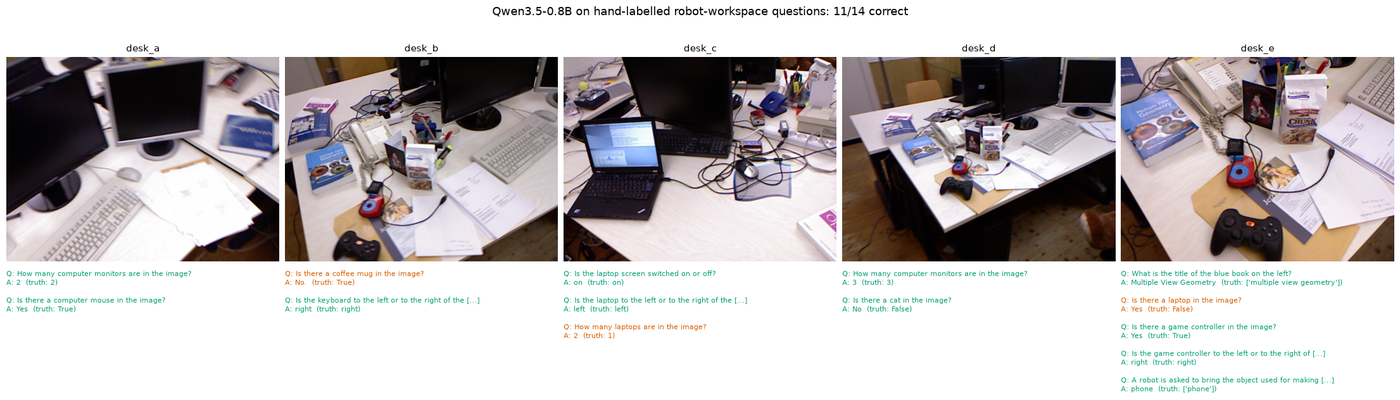

In [8]:
# --- Figure: desk frames with the hand-labelled questions and the model's answers ---
fig, axes = plt.subplots(1, 5, figsize=(22, 6.2))
for ax, key in zip(axes, desk):
    ax.imshow(desk[key])
    ax.axis("off")
    ax.set_title(key, fontsize=11)
    lines = qa[qa.frame == key]
    for j, (_, r) in enumerate(lines.iterrows()):
        q = textwrap.shorten(r.question.replace("Answer with a single number.", ""), 60)
        ax.text(0.0, -0.04 - 0.13 * j, f"Q: {q}\nA: {textwrap.shorten(r.answer, 55)}  (truth: {r.truth})",
                transform=ax.transAxes, va="top", fontsize=8, wrap=True,
                color=viz.color(2, unit=True) if r.correct else viz.color(5, unit=True))
fig.suptitle(f"Qwen3.5-0.8B on hand-labelled robot-workspace questions: {qa.correct.sum()}/{len(qa)} correct", fontsize=13)
viz.savefig(fig, PROJECT, "vlm_desk_qa")
plt.show()

Probe accuracy with 95% confidence intervals against trivial baselines, the count confusion
matrix, and the latency / memory sweep:

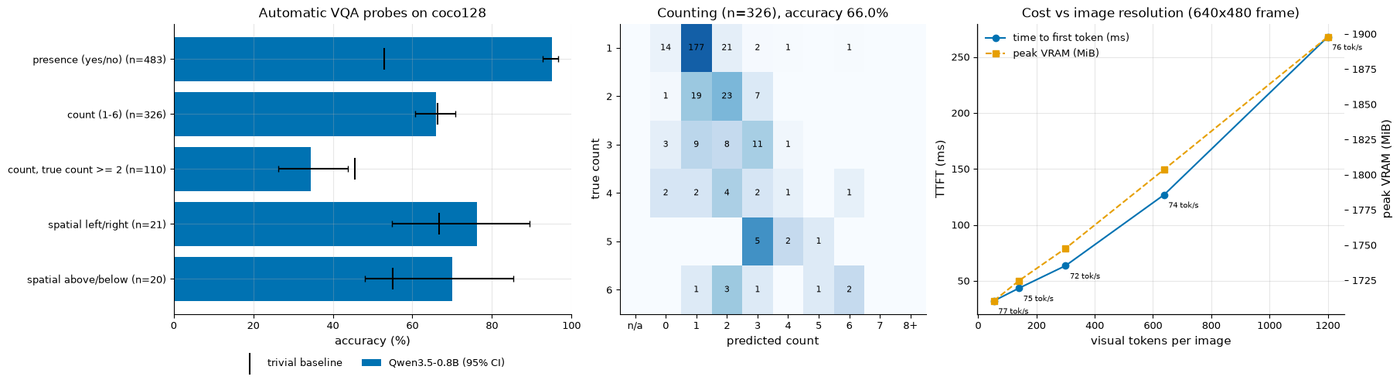

In [9]:
# --- Figure: probe accuracy vs baselines, count confusion, latency/VRAM vs visual tokens ---
fig, axes = plt.subplots(1, 3, figsize=(18, 4.8), gridspec_kw={"width_ratios": [1.3, 1, 1.2]})
ax = axes[0]
yy = np.arange(len(metrics))
ax.barh(yy, 100 * metrics.accuracy, xerr=100 * np.vstack([metrics.accuracy - metrics["95% CI low"],
        metrics["95% CI high"] - metrics.accuracy]), color=viz.color(0, unit=True), capsize=3, label="Qwen3.5-0.8B (95% CI)")
ax.scatter(100 * metrics.baseline, yy, marker="|", s=400, color="k", zorder=3, label="trivial baseline")
ax.set_yticks(yy, [f"{p} (n={n})" for p, n in zip(metrics.index, metrics.n)], fontsize=9)
ax.invert_yaxis()
ax.set(xlabel="accuracy (%)", xlim=(0, 100), title="Automatic VQA probes on coco128")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=2, frameon=False)  # below the axis
ax = axes[1]
cm = pd.crosstab(cnt.truth, cnt.pred.fillna(-1).astype(int).clip(upper=8)).reindex(columns=range(-1, 9), fill_value=0)
ax.imshow(cm.values / cm.values.sum(1, keepdims=True), cmap="Blues", vmin=0, vmax=1, aspect="auto")
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        if cm.values[i, j]:
            ax.text(j, i, cm.values[i, j], ha="center", va="center", fontsize=8)
ax.set_xticks(range(cm.shape[1]), ["n/a"] + [str(c) for c in cm.columns[1:-1]] + ["8+"])
ax.set_yticks(range(cm.shape[0]), cm.index)
ax.grid(False)
ax.set(xlabel="predicted count", ylabel="true count", title=f"Counting (n={len(cnt)}), accuracy {cnt.correct.mean():.1%}")
ax = axes[2]
ax.plot(sweep["visual tokens"], sweep["TTFT (ms)"], "o-", color=viz.color(0, unit=True), label="time to first token (ms)")
ax.set(xlabel="visual tokens per image", ylabel="TTFT (ms)", title="Cost vs image resolution (640x480 frame)")
ax2 = ax.twinx()
ax2.plot(sweep["visual tokens"], sweep["peak VRAM (MiB)"], "s--", color=viz.color(1, unit=True), label="peak VRAM (MiB)")
ax2.set_ylabel("peak VRAM (MiB)")
ax2.grid(False)
for _, r in sweep.iterrows():
    ax.annotate(f"{r['decode tok/s']:.0f} tok/s", (r["visual tokens"], r["TTFT (ms)"]), textcoords="offset points",
                xytext=(4, -12), fontsize=7)
h1, l1 = ax.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, loc="upper left")
viz.savefig(fig, PROJECT, "vlm_probes")
plt.show()

A failure gallery: two hallucinations (the model says "yes" for an absent object), two
counting errors and two spatial errors. The ground-truth boxes of the objects named in the question
are drawn on the image.

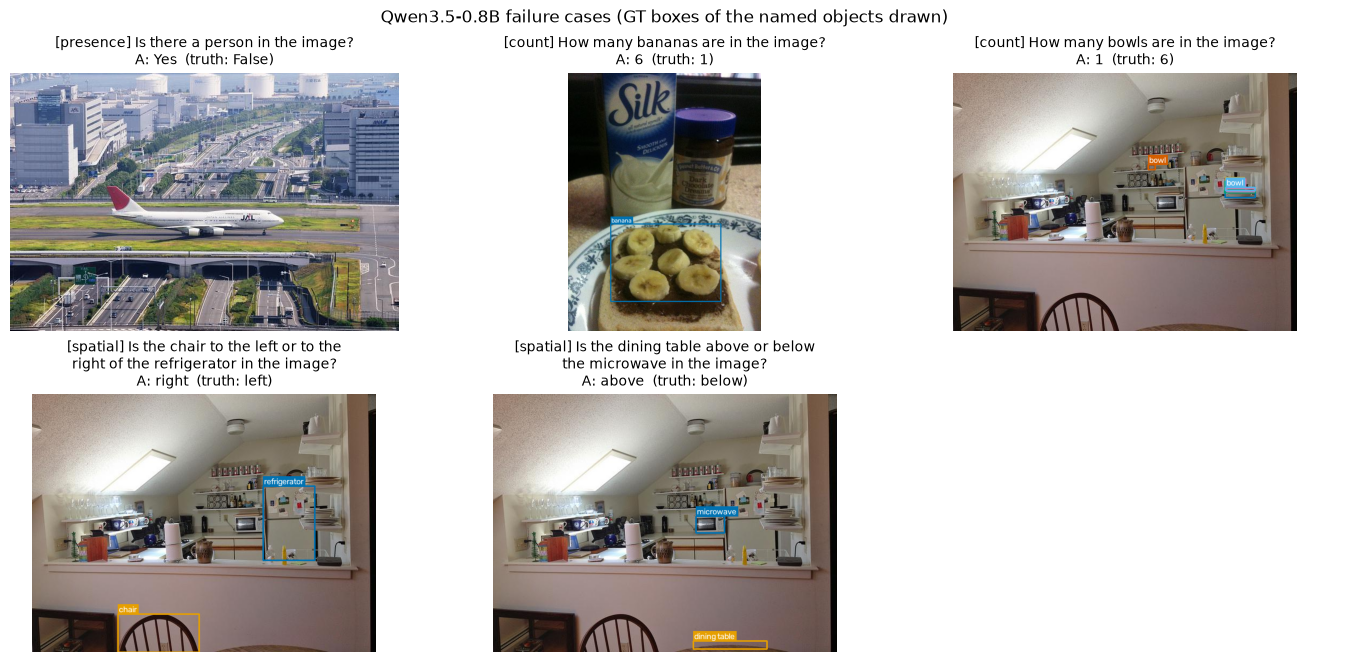

In [10]:
# --- Figure: qualitative failure gallery from the probe results ---
by_name = {it.path.name: it for it in coco}
fails = pd.concat([
    pres[pres.said_yes & ~pres.truth].head(2),
    cnt[~cnt.correct].assign(err=lambda d: (d.pred - d.truth).abs()).sort_values("err", ascending=False).head(2),
    spa[~spa.correct].head(2),
])
panels, titles = [], []
for _, r in fails.iterrows():
    it = by_name[r.image]
    objs = r.object.split(" vs ")
    keep = [i for i, n in enumerate(it.names()) if n in objs]
    panels.append(viz.draw_boxes(np.asarray(vl.load_rgb(it.path)), it.boxes[keep], [it.names()[i] for i in keep]))
    titles.append(textwrap.fill(f"[{r.kind}] {r.question.split('?')[0]}?", 46) + f"\nA: {r.answer!s:.30}  (truth: {r.truth})")
fig = viz.show_images(panels, titles, ncols=3, size=4.6, suptitle="Qwen3.5-0.8B failure cases (GT boxes of the named objects drawn)")
viz.savefig(fig, PROJECT, "vlm_failures")
plt.show()

### Summary table

The table is also saved to `results/vlm_summary.csv`.

In [11]:
# --- Summary table of measured numbers (saved as CSV for the README) ---
native = sweep.loc[sweep["visual tokens"] == 300].iloc[0]
summary = pd.DataFrame([
    ("hand-labelled desk questions correct", f"{qa.correct.sum()} / {len(qa)}"),
    ("presence accuracy (POPE-style, random negatives)", f"{metrics.loc['presence (yes/no)', 'accuracy']:.1%} (n={metrics.loc['presence (yes/no)', 'n']})"),
    ("hallucination rate (yes on absent objects)", f"{pope['hallucination rate (yes on absent)']:.1%}"),
    (f"yes-ratio (truth {pope['true yes-ratio']:.1%})", f"{pope['yes-ratio']:.1%}"),
    ("count accuracy, 1-6 (always-1 baseline)", f"{metrics.loc['count (1-6)', 'accuracy']:.1%} ({metrics.loc['count (1-6)', 'baseline']:.1%})"),
    ("count accuracy, true count >= 2", f"{metrics.loc['count, true count >= 2', 'accuracy']:.1%} (n={metrics.loc['count, true count >= 2', 'n']})"),
    ("spatial left/right accuracy", f"{metrics.loc['spatial left/right', 'accuracy']:.1%} (n={metrics.loc['spatial left/right', 'n']})"),
    ("spatial above/below accuracy", f"{metrics.loc['spatial above/below', 'accuracy']:.1%} (n={metrics.loc['spatial above/below', 'n']})"),
    ("TTFT at 300 visual tokens (ms)", f"{native['TTFT (ms)']:.0f}"),
    ("decode speed at 300 visual tokens (tok/s)", f"{native['decode tok/s']:.1f}"),
    ("weights on GPU (MiB, bf16)", f"{mem_load.delta_mb:.0f}"),
    ("peak VRAM, 300 / 1200 visual tokens (MiB)", f"{native['peak VRAM (MiB)']:.0f} / {sweep['peak VRAM (MiB)'].iloc[-1]:.0f}"),
    ("probe benchmark: mean latency per question (s)", f"{run['mean_latency_s']:.3f}"),
], columns=["metric", "value"]).set_index("metric")
summary.to_csv(RESULTS / "vlm_summary.csv")
display(summary)

,value
metric,
hand-labelled desk questions correct,11 / 14
"presence accuracy (POPE-style, random negatives)",95.0% (n=483)
hallucination rate (yes on absent objects),0.4%
yes-ratio (truth 47.0%),42.4%
"count accuracy, 1-6 (always-1 baseline)",66.0% (66.3%)
"count accuracy, true count >= 2",34.5% (n=110)
spatial left/right accuracy,76.2% (n=21)
spatial above/below accuracy,70.0% (n=20)
TTFT at 300 visual tokens (ms),64


### Takeaways

* **A real VLM fits easily in 8 GB.** Qwen3.5-0.8B (853 M parameters) needs 1,656 MiB of bf16
  weights and peaks at 1,748 MiB for one 640 x 480 frame (300 visual tokens) and 1,898 MiB at
  1,200 visual tokens. The hybrid decoder keeps a KV cache on only 6 of its 24 layers (12 KiB per token).
* **Visual tokens set the time to first token.** TTFT grew from 32 ms (54 visual tokens) to
  64 ms (300) and 268 ms (1,200), while decode speed stayed flat at about
  72 tok/s in this run. Decode speed is the least stable number: on the same day it
  measured 39.2, 51.9, 80.1 and 72.2 tok/s at 300 visual tokens in 4 runs, while TTFT stayed
  between 64 and 72 ms. At batch size 1 a 0.8 B model does so little GPU work per token that
  CPU-side overhead (shared with other jobs) matters.
* **Free-form answers are fluent but unreliable.** 11 of 14 hand-labelled desk questions were
  correct. It read the book title ("Multiple View Geometry") and chose the phone for "the object
  used for making phone calls", but missed the coffee mug on `desk_b`, counted 2 laptops on
  `desk_c` (truth 1) and hallucinated a laptop on `desk_e`. Asked for graspable objects on
  `desk_b`, it got stuck repeating "mouse" until the token limit: parse and validate VLM output
  before a robot acts on it.
* **Presence questions are its strength.** 95.0% accuracy on 483 POPE-style probes (95% CI
  92.7-96.6%, majority baseline 53.0%). The model is conservative: yes-ratio 42.4% against a true
  47.0%, recall of "yes" 0.899, and a hallucination rate of only 0.4% on *random* absent
  objects. Exercise 3 shows that it rises when the absent object is one that usually co-occurs
  with the scene.
* **Counting and spatial relations are weak.** Count accuracy is 66.0%, the same as always
  answering "1" (66.3%). For true counts of 2 or more it drops to 34.5%, below always answering
  "2" (45.5%). Left/right (76.2%, n=21) and above/below (70.0%, n=20) beat their majority baselines
  (66.7%, 55.0%), but the 95% intervals overlap them: far more probes would be needed to claim a
  real skill.
* **Labels can be wrong too.** Some "failures" in the gallery are label issues (a plate of banana
  slices is one "banana" box in COCO), so automatic probes need a quick visual audit.

## Exercises

Solutions: `python projects/13_vision_language/solutions/ex03_small_vlm.py` (it also runs the
low-resolution probe benchmark of Exercise 2 if its CSV does not exist yet).

**Exercise 1: prompting for counting.** For the count probes with a true count $\geq 2$, compare
the direct question with a "count step by step" prompt: *"Count the {plural} in the image one by
one, then give the total as 'Total: N'."* (parse the number after "Total:", and allow more new
tokens). Does reasoning in text help a 0.8 B model count?

In [12]:
# --- Exercise 1: direct vs step-by-step counting prompts ---
# TODO: for each row of cnt[cnt.truth >= 2], ask both prompts with vlm.ask(...) and compare accuracy.

**Exercise 2: resolution vs accuracy.** Re-run the probe benchmark with a quarter of the
pixels, `python projects/13_vision_language/scripts/eval_vqa_probes.py --max-visual-tokens 75 --tag lowres`,
and compare the accuracy per probe type and the mean latency with the native-resolution run.

In [13]:
# --- Exercise 2: compare results/vqa_probes.csv with results/vqa_probes_lowres.csv ---
# TODO: load both CSVs and tabulate accuracy per kind and mean latency_s / visual_tokens.

**Exercise 3: adversarial hallucination probes.** POPE's *adversarial* setting draws the absent
objects from classes that frequently **co-occur** with the present ones (a "fork" in a kitchen
without a fork). Build co-occurrence counts over coco128, generate 2 adversarial negatives per
image and compare the hallucination rate with the random negatives above.

In [14]:
# --- Exercise 3: co-occurrence-based (adversarial) absent-object questions ---
# TODO: count class co-occurrences over `coco`, pick for each image the 2 absent classes that
# co-occur most with its present classes, ask "Is there a ...?" and measure the yes-rate.